# 심화 05 · 영상 처리 흐름과 FPS·크기·평균 처리시간

현재 수정된 `video_ops.py`와 `main.py`를 실행하고 원본 및 처리 영상의 실제 정보를 비교합니다.

현재 구현은 **원본 320×240 → 처리 영상 160×120**입니다. 원본 크기를 유지하는 실험과 구분해 기록합니다.

필요 패키지: `opencv-python`, `numpy`, `pandas`, `matplotlib`, `IPython`. 패키지가 설치된 프로젝트 커널에서 위에서부터 실행하세요. 실행하면 `outputs/edge.avi`와 `outputs/video_report.json`이 다시 생성됩니다.

## 1. 처리 흐름

영상 열기 → 원본 FPS 읽기 → 160×120 MJPG Writer 생성 → 프레임 읽기 → 처리 → 저장 → 자원 종료 → 출력 재읽기 → 보고서 저장.

프레임 처리 함수는 다음 순서로 연결됩니다.

1. INTER_AREA로 160×120 축소
2. BGR → Gray 변환
3. GaussianBlur: 3×3, sigmaX=0
4. Blur 결과에 Canny: 80/160
5. 저장용으로 Gray → BGR 3채널 변환

마지막 변환은 원래 색상을 복원하는 것이 아니라 동일한 Edge 값을 3채널에 배치하는 것입니다. Writer의 `(너비, 높이)`는 함수 반환 프레임 크기와 일치해야 합니다.

In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/03_심화/05_video/main.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/03_심화/05_video"


## 2. 프레임 처리 함수

현재 파일의 구현을 그대로 사용합니다. 함수 호출만으로 파일을 열거나 저장하지 않으며 입력 프레임에서 처리 결과를 반환합니다.

In [2]:
import cv2

def process_frame(frame):
    """컬러 Frame을 고정 크기의 Edge 컬러 Frame으로 바꿉니다."""
    # >>> TODO H05
    # Resize160×120→Gray→Gaussian3×3→Canny80/160 순서로 edge를 만드세요. 파일 열기·종료는 main이 담당합니다.
    small=cv2.resize(frame,(160,120), interpolation=cv2.INTER_AREA)
    gray=cv2.cvtColor(small,cv2.COLOR_BGR2GRAY)
    blur=cv2.GaussianBlur(gray, (3,3), 0)
    canny=cv2.Canny(blur, 80, 160)
    # <<< TODO H05
    return cv2.cvtColor(canny,cv2.COLOR_GRAY2BGR)


## 3. 영상 변환 실행과 시간 측정

아래 코드는 현재 `main.py`의 실행 부분입니다. 노트북에서는 `__file__` 경로를 `exercise`로 대체하고, 모듈 import 대신 위 셀에서 정의한 같은 함수를 사용합니다.

- **mean_process_ms**: `process_frame(frame)` 호출만 측정한 프레임별 시간의 평균입니다. Resize·Gray·Blur·Canny·BGR 변환을 포함합니다.
- **wall_s**: read·처리·write 반복과 자원 종료를 포함합니다. 입력/Writer 초기화 및 출력 재읽기·보고서 저장은 제외합니다.
- FPS는 저장된 영상의 재생 속도입니다. 프레임 처리 속도와 구분합니다.

시간은 이 환경에서 한 번 실행한 관측값이며, 부하와 OpenCV 스레드 설정 등에 따라 재실행 시 달라집니다.

In [3]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

import csv
import json
from time import perf_counter
Path("outputs").mkdir(exist_ok=True)

# 위 셀에 정의한 동일한 process_frame 함수를 사용합니다.
cap=cv2.VideoCapture("../data/sample.avi");fps=cap.get(cv2.CAP_PROP_FPS)
writer=cv2.VideoWriter("outputs/edge.avi",cv2.VideoWriter_fourcc(*"MJPG"),fps,(160,120))
count=0;processing=[];start_all=perf_counter()
while cap.isOpened() and writer.isOpened():
    ok,frame=cap.read()
    if not ok: break
    start=perf_counter();result=process_frame(frame);processing.append(perf_counter()-start)
    writer.write(result);count+=1
cap.release();writer.release();wall=perf_counter()-start_all
check=cv2.VideoCapture("outputs/edge.avi")
report={"frames_written":count,"reopened_frames":int(check.get(7)),"fps":check.get(5),"width":int(check.get(3)),"height":int(check.get(4)),"wall_s":wall,"mean_process_ms":float(np.mean(processing)*1000)}
check.release()
Path("outputs/video_report.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
print("Frame/FPS/크기:",report["reopened_frames"],report["fps"],(report["width"],report["height"]))
print("wall은 read·처리·write 포함, mean_process는 Frame 처리만 포함합니다.")


Frame/FPS/크기: 48 12.0 (160, 120)
wall은 read·처리·write 포함, mean_process는 Frame 처리만 포함합니다.


## 4. 원본·처리 영상 비교표

두 영상을 실제로 끝까지 디코딩해 프레임 수를 세고, 처음과 마지막 프레임을 확인합니다. 이 재읽기는 위 처리시간 측정에 포함되지 않습니다.

원본은 변환하지 않은 입력이므로 **평균 변환 처리시간은 측정 대상이 아니며 N/A**로 표시합니다. 원본의 프레임 간격 `1000/FPS`를 처리시간으로 기록하지 않습니다. 처리 영상의 평균값은 방금 실행한 보고서에서 읽습니다.

In [4]:
def inspect_video(path):
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f"영상 열기 실패: {path.name}")
    try:
        fps_value = capture.get(cv2.CAP_PROP_FPS)
        width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        frame_count = 0
        first = last = None
        while True:
            ok, frame = capture.read()
            if not ok:
                break
            assert frame.shape == (height, width, 3)
            if first is None:
                first = frame.copy()
            last = frame.copy()
            frame_count += 1
    finally:
        capture.release()
    if frame_count == 0:
        raise RuntimeError(f"디코딩된 프레임이 없습니다: {path.name}")
    return {"fps": fps_value, "width": width, "height": height,
            "frames": frame_count, "first": first, "last": last}

saved_report = json.loads(Path("outputs/video_report.json").read_text(encoding="utf-8"))
original_info = inspect_video(exercise.parent / "data/sample.avi")
processed_info = inspect_video(exercise / "outputs/edge.avi")
comparison = pd.DataFrame([
    {"영상": "원본", "FPS (재생)": original_info["fps"],
     "크기 (너비×높이)": f'{original_info["width"]}×{original_info["height"]}',
     "디코딩 프레임 수": original_info["frames"],
     "재생시간 (초)": original_info["frames"] / original_info["fps"],
     "평균 프레임 변환시간 (ms)": float("nan")},
    {"영상": "처리", "FPS (재생)": processed_info["fps"],
     "크기 (너비×높이)": f'{processed_info["width"]}×{processed_info["height"]}',
     "디코딩 프레임 수": processed_info["frames"],
     "재생시간 (초)": processed_info["frames"] / processed_info["fps"],
     "평균 프레임 변환시간 (ms)": saved_report["mean_process_ms"]},
])
display(comparison.style.format({"평균 프레임 변환시간 (ms)": "{:.6f}"}, na_rep="N/A"))
timing = pd.DataFrame([
    {"측정 항목": "process_frame 평균 (ms/frame)", "관측값": saved_report["mean_process_ms"]},
    {"측정 항목": "전체 반복 wall (초)", "관측값": saved_report["wall_s"]},
    {"측정 항목": "wall / 저장 호출 프레임 수 (ms/frame)",
     "관측값": saved_report["wall_s"] * 1000 / saved_report["frames_written"]},
])
display(timing)
print("N/A: 원본은 변환 대상이 아니므로 원본 자체의 변환 처리시간을 측정하지 않았습니다.")

,영상,FPS (재생),크기 (너비×높이),디코딩 프레임 수,재생시간 (초),평균 프레임 변환시간 (ms)
0,원본,12.000000,320×240,48,4.000000,N/A
1,처리,12.000000,160×120,48,4.000000,0.401801


,측정 항목,관측값
0,process_frame 평균 (ms/frame),0.401801
1,전체 반복 wall (초),0.067754
2,wall / 저장 호출 프레임 수 (ms/frame),1.411537


N/A: 원본은 변환 대상이 아니므로 원본 자체의 변환 처리시간을 측정하지 않았습니다.


## 5. 원본과 처리 결과의 처음·마지막 프레임

표시 공간을 맞춘 비교이며 저장된 영상 해상도는 위 표의 값입니다. MJPG는 손실 압축이므로 재읽기한 Edge 프레임의 픽셀이 저장 전 배열과 완전히 같다고 가정하지 않습니다.

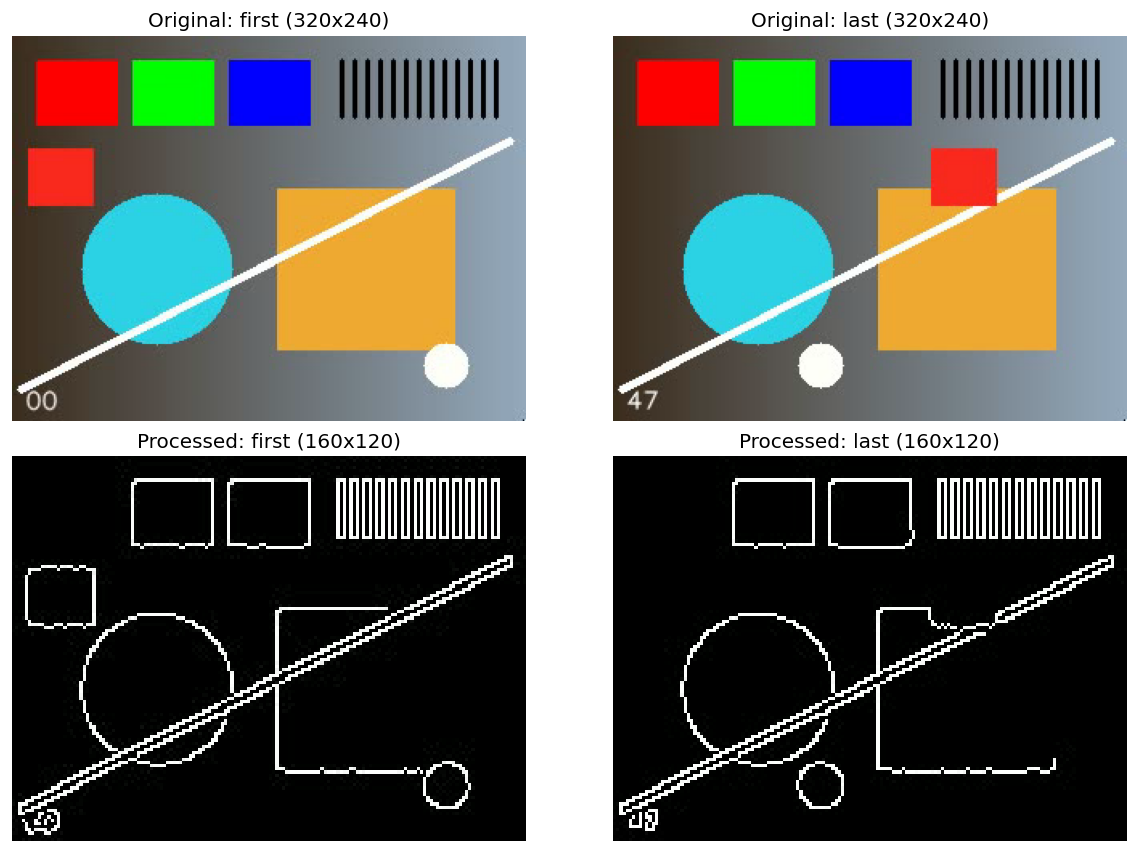

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
for row, (name, info) in enumerate([("Original", original_info), ("Processed", processed_info)]):
    for col, key in enumerate(["first", "last"]):
        axes[row, col].imshow(cv2.cvtColor(info[key], cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"{name}: {key} ({info['width']}x{info['height']})")
        axes[row, col].axis("off")
plt.show()

## 6. 결과 검증과 해석

현재 저장 코드는 `write()` 호출 횟수를 셉니다. 저장 성공 여부를 별도로 확인하기 위해 여기서는 영상 전체를 재읽은 프레임 수와 비교합니다.

현재 조건에서는 48프레임·12 FPS를 유지하며 영상 크기는 320×240에서 160×120으로 바뀝니다. 재생시간은 두 영상 모두 4초입니다. 평균 처리시간이 짧아도 저장 영상의 재생 FPS가 자동으로 증가하지는 않습니다.

Gray 변환은 색상 정보를 제거하고, 축소는 공간 해상도를 낮추며, Canny 결과는 경계 중심 표현입니다. 이 영상만으로 객체 검출을 완료한 것은 아닙니다.

In [6]:
assert original_info["frames"] == processed_info["frames"] == saved_report["frames_written"] == 48
assert saved_report["reopened_frames"] == processed_info["frames"]
assert original_info["fps"] == processed_info["fps"] == saved_report["fps"] == 12
assert (original_info["width"], original_info["height"]) == (320, 240)
assert (processed_info["width"], processed_info["height"]) == (160, 120)
assert (saved_report["width"], saved_report["height"]) == (160, 120)
assert np.isfinite(saved_report["mean_process_ms"]) and saved_report["mean_process_ms"] >= 0
assert saved_report["wall_s"] > 0
print("검증 통과: 프레임 수·FPS·해상도·시간 기록 일치")
os.chdir(notebook_start)

검증 통과: 프레임 수·FPS·해상도·시간 기록 일치
